# **Proyecto ACA 2**

Dataset seleccionado: **UCI Predict Students Dropout**

**EQUIPO DE TRABAJO**

- CRISTIAN ALEJANDRO PEREZ DEJOY
- JOSE RICARDO OSORIO CACERES
- SANDRA MILENA GUTIÉRREZ RODRÍGUEZ



# **Contexto**

En el ámbito de la educación superior, la **deserción estudiantil** representa un problema social y económico crítico. Las instituciones educativas suelen reaccionar cuando el estudiante ya ha abandonado las aulas. La propuesta analítica consiste en **anticiparse al abandono escolar** mediante la transformación de datos históricos en conocimiento predictivo.

Al aplicar un modelo de aprendizaje supervisado, el objetivo es identificar patrones de riesgo tempranos para que la institución pueda intervenir de manera preventiva mediante tutorías, apoyos financieros o acompañamiento académico.

## Naturaleza del Dataset
- **Tipo de Problema**: Es un problema de Aprendizaje Supervisado de Clasificación.
- **Variable Objetivo (Target)**: Corresponde a la columna dependiente $y$, la cual clasifica al estudiante en una de tres categorías:
    - `Dropout` (Estudiante que abandonó sus estudios / Desertor).
    - `Graduate` (Estudiante que culminó con éxito su carrera / Graduado).
    - `Enrolled` (Estudiante activo que continúa matriculado) **No aplica para el analisis.**

# **PASO 1: Exploración y EDA**

## Carga de datos


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

In [2]:
# Cargar datos desde dataframe

file_id = '1hibMQVZCIThMb-rM3A2J7zUBj1hwL6PH'
drive_direct_download_url = f'https://drive.google.com/uc?export=download&id={file_id}'

try:
    df_url = pd.read_csv(drive_direct_download_url, sep=';')
    print(f"Dataset cargado exitosamente desde la URL de Google Drive: {drive_direct_download_url}")
except Exception as e:
    print(f"Error al cargar el archivo desde la URL de Google Drive: {e}")
    print("Asegúrate de que el 'file_id' sea correcto y que el archivo esté compartido públicamente.")


Dataset cargado exitosamente desde la URL de Google Drive: https://drive.google.com/uc?export=download&id=1hibMQVZCIThMb-rM3A2J7zUBj1hwL6PH


## Exploración inicial de datos

In [8]:
# Visualizar dataframe (5 primeras filas del dataframe)
print("Primeras filas del archivo:\n")
df_url.head()

Primeras filas del archivo:



,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [9]:
# Resumen de información sobre el DataFrame
print("\nInformación del DataFrame:")
df_url.info()


Información del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification  

In [10]:
# Estadísticas descriptivas del DataFrame
print("\nEstadísticas descriptivas:")
df_url.describe()


Estadísticas descriptivas:


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


# Paso 2: Limpieza de datos

## Manejo de datos en blanco, tabulaciones, etc.

In [3]:
# Manejo de datos en blanco, tabulaciones, etc.
data = df_url.copy()

# Reemplazar espacios vacíos y caracteres de interrogación por valores NaN reales de NumPy
data.replace(r'^\s*$', np.nan, regex=True, inplace=True)
data.replace('?', np.nan, inplace=True)
data.columns = data.columns.str.strip()

print("Copia de trabajo creada exitosamente y manejo de datos en blanco realizado.")


Copia de trabajo creada exitosamente y manejo de datos en blanco realizado.


## Manejo de nulos

In [12]:
# Calcular nulos totales y sus porcentajes
total_nulos = data.isna().sum()
porcentaje_nulos = (data.isna().mean() * 100).round(2)

# Consolidar la información en un DataFrame de auditoría ordenado de mayor a menor
reporte_nulos = pd.DataFrame({
    'Nulos Totales': total_nulos,
    'Porcentaje (%)': porcentaje_nulos
}).sort_values(by='Nulos Totales', ascending=False)

# Mostrar solo las columnas que presentan valores faltantes
reporte_nulos[reporte_nulos['Nulos Totales'] > 0]

,Nulos Totales,Porcentaje (%)


El dataframe no cuenta con valores nulos

## Manejo de duplicados

In [13]:
# Identificar valores faltantes
print("\nValores Faltantes:")
print(data.isnull().sum())


Valores Faltantes:
Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                          

In [14]:
# Ver cuántas filas duplicadas existen en total en el Dataframe
print("Cantidad de duplicados:", data.duplicated().sum())

# Mostrar las filas que están repetidas
filas_duplicadas = data[data.duplicated(keep=False)]
print("Filas duplicadas: ", filas_duplicadas)

Cantidad de duplicados: 0
Filas duplicadas:  Empty DataFrame
Columns: [Marital status, Application mode, Application order, Course, Daytime/evening attendance, Previous qualification, Previous qualification (grade), Nacionality, Mother's qualification, Father's qualification, Mother's occupation, Father's occupation, Admission grade, Displaced, Educational special needs, Debtor, Tuition fees up to date, Gender, Scholarship holder, Age at enrollment, International, Curricular units 1st sem (credited), Curricular units 1st sem (enrolled), Curricular units 1st sem (evaluations), Curricular units 1st sem (approved), Curricular units 1st sem (grade), Curricular units 1st sem (without evaluations), Curricular units 2nd sem (credited), Curricular units 2nd sem (enrolled), Curricular units 2nd sem (evaluations), Curricular units 2nd sem (approved), Curricular units 2nd sem (grade), Curricular units 2nd sem (without evaluations), Unemployment rate, Inflation rate, GDP, Target]
Index: []

[0 row

La DataFrame no cuenta con filas duplicadas

## Manejo de formato de fecha

**Ausencia de campos de fecha**: Al inspeccionar las columnas que componen el dataset, **no existe ninguna columna que contenga fechas, horas o marcas de tiempo**, todas las características de este dataset son valores numéricos.

In [4]:
# 1. Filtrar y Excluir por completo a los estudiantes 'Enrolled' del DataFrame original
data = data[data['Target'] != 'Enrolled'].copy()

# 2. Definir el mapa de conversión binario limpio (Graduate = 1, Dropout = 0)
mapa_target = {'Graduate': 1, 'Dropout': 0}

# 3. Crear la nueva columna mapeando los valores en el DataFrame ya filtrado
data['Target_Binario'] = data['Target'].map(mapa_target)

# 4. Convertir la columna a tipo entero ('int') para garantizar que no tenga el decimal .0
data['Target_Binario'] = data['Target_Binario'].astype(int)

# --- Verificación de los cambios ---
print("Registros tras excluir 'Enrolled':", len(data))


Registros tras excluir 'Enrolled': 3630


## Normalizar textos

In [5]:
# Identificar de forma automática las columnas que contienen texto (tipo object)
columnas_categoricas = data.select_dtypes(include=['object']).columns

print("Columnas categóricas a normalizar:", list(columnas_categoricas))

# Aplicar limpieza: eliminar espacios en blanco extremos (.strip())
# y estandarizar el texto con la primera letra en mayúscula (.str.title())
for col in columnas_categoricas:
    # Eliminamos espacios fantasmas y aseguramos formato tipo Título
    data[col] = data[col].astype(str).str.strip().str.title()

# Mostrar los valores únicos de una variable clave como control de calidad
print("\nValores únicos normalizados en 'Target':")
print(data['Target'].unique())

Columnas categóricas a normalizar: ['Target']

Valores únicos normalizados en 'Target':
<ArrowStringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str


/tmp/ipykernel_12612/534089979.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = data.select_dtypes(include=['object']).columns


In [17]:
# 1. Filtrar y Excluir por completo a los estudiantes 'Enrolled' del DataFrame original
data = data[data['Target'] != 'Enrolled'].copy()

# 2. Definir el mapa de conversión binario limpio (Graduate = 1, Dropout = 0)
mapa_target = {'Graduate': 1, 'Dropout': 0}

# 3. Crear la nueva columna mapeando los valores en el DataFrame ya filtrado
data['Target_Binario'] = data['Target'].map(mapa_target)

# 4. Convertir la columna a tipo entero ('int') para garantizar que no tenga el decimal .0
data['Target_Binario'] = data['Target_Binario'].astype(int)

# --- Verificación de los cambios ---
print("Registros tras excluir 'Enrolled':", len(data))

Registros tras excluir 'Enrolled': 3630


Se excluyen los estudiantes matriculados (Enrolled) para centrar el análisis y el modelado exclusivamente en el desenlace final (Graduación vs. Deserción)

## Inserción del dataset limpio en SQLite

Una vez terminada la limpieza, el DataFrame limpio se inserta en una base de datos **SQLite** (`UCI_Predict_Students_Dropout.db`, tabla `students_dropout_clean`) y luego se consulta con SQL desde Python para alimentar el DataFrame de trabajo usado en el modelado.

In [6]:
import sqlite3
from pathlib import Path

DB_PATH = Path("UCI_Predict_Students_Dropout.db")
TABLE_NAME = "students_dropout_clean"

# Inserción: crea (o reemplaza) la tabla con el dataset ya limpio
with sqlite3.connect(DB_PATH) as conn:
    data.to_sql(TABLE_NAME, conn, if_exists="replace", index=False)
    filas_insertadas = conn.execute(f'SELECT COUNT(*) FROM "{TABLE_NAME}"').fetchone()[0]

print(f"Base de datos: {DB_PATH.resolve()}")
print(f"Registros limpios insertados en '{TABLE_NAME}': {filas_insertadas}")


Base de datos: /ssd_datos/Projects/Python/ACA_1_AprendizajeAutomatico/UCI_Predict_Students_Dropout.db
Registros limpios insertados en 'students_dropout_clean': 3630


In [7]:
# Consulta SQL desde Python: el resultado alimenta el DataFrame de trabajo
query = f'SELECT * FROM "{TABLE_NAME}"'

with sqlite3.connect(DB_PATH) as conn:
    data = pd.read_sql_query(query, conn)

print(f"Registros recuperados con SQL: {len(data)} | Columnas: {data.shape[1]}")
data.head()


Registros recuperados con SQL: 3630 | Columnas: 38


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Target_Binario
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,0
1,1,15,1,9254,1,1,160.0,1,1,3,...,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,1
2,1,1,5,9070,1,1,122.0,1,37,37,...,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,0
3,1,17,2,9773,1,1,122.0,1,38,37,...,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,1
4,2,39,1,8014,0,1,100.0,1,37,38,...,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,1


## Exploración final después de la limpieza

In [20]:
data.head(20)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Target_Binario
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,0
1,1,15,1,9254,1,1,160.0,1,1,3,...,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,1
2,1,1,5,9070,1,1,122.0,1,37,37,...,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,0
3,1,17,2,9773,1,1,122.0,1,38,37,...,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,1
4,2,39,1,8014,0,1,100.0,1,37,38,...,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,1
5,2,39,1,9991,0,19,133.1,1,37,37,...,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate,1
6,1,1,1,9500,1,1,142.0,1,19,38,...,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate,1
7,1,18,4,9254,1,1,119.0,1,37,37,...,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout,0
8,1,1,3,9238,1,1,137.0,62,1,1,...,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate,1
9,1,1,1,9238,1,1,138.0,1,1,19,...,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout,0


* **¿Influye la edad de matriculación en la deserción escolar?**


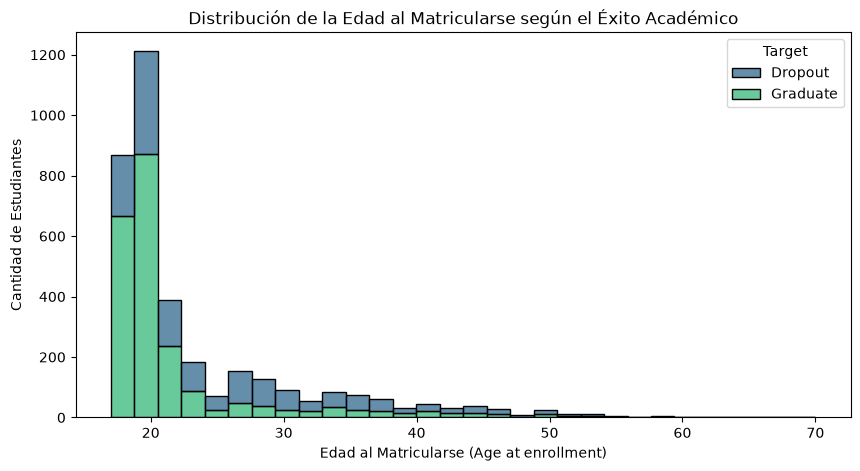

In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='Age at enrollment', hue='Target', multiple='stack', bins=30, palette='viridis')
plt.title('Distribución de la Edad al Matricularse según el Éxito Académico')
plt.xlabel('Edad al Matricularse (Age at enrollment)')
plt.ylabel('Cantidad de Estudiantes')
plt.show()

Concentración de Jóvenes e Ingreso Inmediato: Existe una altísima concentración de estudiantes que se matriculan a una edad temprana (entre los 18 y 21 años aproximadamente). Este grupo representa la gran mayoría de la población estudiantil y muestra visualmente una mayor proporción correspondientes a estudiantes graduados (Graduate).

Aumento del Riesgo de Deserción con la Edad: A medida que aumenta la edad de matriculación (estudiantes mayores de 23 o 25 años), la proporción de deserción (Dropout) se incrementa de manera muy notable en comparación con la de graduados. Las barras se vuelven dominantemente representativas de la deserción.

### **Conclusión en palabras simples: edad al matricularse**

La gráfica cuenta cuántos estudiantes entraron a cada edad y los separa por color según si se graduaron o desertaron. La mayoría entra muy joven, entre los 18 y 21 años, y en ese grupo predominan los graduados. A partir de los 23-25 años pesa más el color de la deserción: **quien se matricula más tarde tiene más riesgo de abandonar**, probablemente por compromisos laborales o familiares. Es un patrón observado en los datos, no una prueba de que la edad sea la causa.

*   **¿Existe una diferencia significativa en los promedios de calificaciones entre los alumnos que se gradúan y los que desertan?**


/tmp/ipykernel_8600/3795106381.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Target', y='Curricular units 2nd sem (grade)', palette='Pastel1')


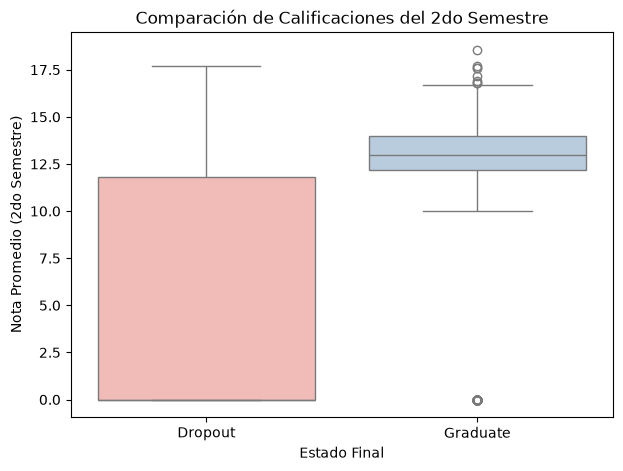

In [22]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x='Target', y='Curricular units 2nd sem (grade)', palette='Pastel1')
plt.title('Comparación de Calificaciones del 2do Semestre')
plt.xlabel('Estado Final')
plt.ylabel('Nota Promedio (2do Semestre)')
plt.show()

Fuerte Relación entre Rendimiento y Éxito Académico: Existe una diferencia sumamente marcada en las calificaciones del segundo semestre entre ambos grupos. El rendimiento académico durante este periodo es un indicador crítico e inmediato del resultado final del estudiante.

Estabilidad en los Estudiantes Graduados (Graduate): La gran mayoría de los estudiantes que logran graduarse mantienen un rendimiento académico alto y constante. La caja se concentra estrechamente en un rango de notas aprobatorias estables (principalmente entre 12 y 14 puntos), con muy poca dispersión hacia valores bajos.

### **Conclusión en palabras simples: notas del segundo semestre**

Cada caja resume las notas de un grupo: la línea del medio es la nota típica y la caja contiene a la mitad central de los estudiantes. Los graduados tienen notas altas y parecidas entre sí (alrededor de 12 a 14), mientras que los desertores tienen notas más bajas y muchos están cerca de 0, es decir, dejaron de cursar o no aprobaron. **Si las notas del segundo semestre caen, el abandono es mucho más probable.** Como esa nota solo existe cuando el semestre ya se cursó, sirve para detectar el riesgo a mitad de la carrera, no al inicio.

# **PASO 3: Modelado Clásico**


In [23]:
print("Distribución de la nueva variable objetivo (Target_Binario):")
print(data['Target_Binario'].value_counts())

Distribución de la nueva variable objetivo (Target_Binario):
Target_Binario
1    2209
0    1421
Name: count, dtype: int64


In [8]:
# Definir el orden de las nueve variables usadas también por el formulario de Streamlit
FEATURE_COLUMNS = [
    "Age at enrollment",
    "Admission grade",
    "Displaced",
    "Debtor",
    "Tuition fees up to date",
    "Scholarship holder",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
]

# Separación de características (X) y etiqueta (y)
X = data[FEATURE_COLUMNS].copy()
y = data["Target_Binario"]

print(f"Características para los modelos: {len(FEATURE_COLUMNS)}")
print("Orden de columnas compatible con Streamlit:")
print(list(X.columns))

Características para los modelos: 9
Orden de columnas compatible con Streamlit:
['Age at enrollment', 'Admission grade', 'Displaced', 'Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)']


In [9]:
# Datos en 80% para entrenar y 20% para evaluar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Datos de entrenamiento: {X_train.shape} registros")
print(f"Datos de prueba: {X_test.shape} registros")

Datos de entrenamiento: (2904, 9) registros
Datos de prueba: (726, 9) registros


## **ÁRBOL DE DECISIÓN**

In [10]:
# Inicializar el modelo de Árbol de Decisión
# Usamos max_depth para evitar que el árbol crezca infinito y se sobreajuste (overfitting)
modelo_arbol = DecisionTreeClassifier(max_depth=5, random_state=42)

# Entrenar el modelo con los datos de entrenamiento
modelo_arbol.fit(X_train, y_train)

# Realizar predicciones con los datos de prueba
predicciones_arbol = modelo_arbol.predict(X_test)

# Evaluar el rendimiento del modelo
print("Exactitud (Accuracy):", accuracy_score(y_test, predicciones_arbol))
print("\nReporte de Clasificación:\n", classification_report(y_test, predicciones_arbol))

Exactitud (Accuracy): 0.8801652892561983

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.88      0.80      0.84       284
           1       0.88      0.93      0.90       442

    accuracy                           0.88       726
   macro avg       0.88      0.87      0.87       726
weighted avg       0.88      0.88      0.88       726



El Árbol de Decisión se entrenó con las nueve variables predictoras seleccionadas y se evaluó sobre el conjunto de prueba. La exactitud y el reporte de clasificación deben interpretarse con los valores que se impriman al volver a ejecutar el notebook; los resultados anteriores correspondían al modelo entrenado con todas las características.

## **REGRESIÓN LOGISTICA**

In [11]:
# Escalar los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Inicializar el modelo
modelo_logistico = LogisticRegression(max_iter=500, class_weight='balanced', random_state=42)

#Entrenar con los datos ESCALADOS
modelo_logistico.fit(X_train_scaled, y_train)

# Predecir con los datos ESCALADOS
predicciones_regresion = modelo_logistico.predict(X_test_scaled)

# Evaluar
print("Exactitud (Accuracy):", accuracy_score(y_test, predicciones_regresion))
print(
    "\nReporte de Clasificación:\n", classification_report(y_test, predicciones_regresion)
)

Exactitud (Accuracy): 0.8856749311294766

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.87      0.84      0.85       284
           1       0.90      0.92      0.91       442

    accuracy                           0.89       726
   macro avg       0.88      0.88      0.88       726
weighted avg       0.89      0.89      0.89       726



La Regresión Logística se entrena con las nueve variables seleccionadas, escaladas mediante un `StandardScaler` ajustado exclusivamente con `X_train`. La exactitud y el reporte de clasificación se deben tomar de las salidas actualizadas tras volver a ejecutar el notebook; no se deben reutilizar como resultados vigentes los valores del modelo anterior con todas las características.

 # **PASO 4: Evaluación de Métricas**

## **ÁRBOL DE DECISIÓN**

In [28]:
# El modelo realiza las predicciones usando el set de prueba (X_test)
y_pred = modelo_arbol.predict(X_test)

# Calcular e imprimir la Exactitud global (Accuracy)
accuracy = accuracy_score(y_test, y_pred)
print(f"1. Exactitud Global (Accuracy): {accuracy:.4f}")
print(f"   -> El {accuracy*100:.2f}% de todas las predicciones del modelo fueron correctas.\n")

# Mostrar la Matriz de Confusión Estructurada
matriz_cm = confusion_matrix(y_test, y_pred)
print("2. Matriz de Confusión Estructurada:")
print(matriz_cm)
print("\nDesglose de la matriz aplicado a los estudiantes:")

# Extraer de forma automática los valores reales
tn, fp, fn, tp = matriz_cm.ravel()

print(f"   * Verdaderos Negativos (TN): {tn} -> Estudiantes en deserción correctamente identificados.")
print(f"   * Falsos Positivos     (FP): {fp} -> Estudiantes que desertaron, pero el modelo predijo que se graduarían (Riesgo alto).")
print(f"   * Falsos Negativos     (FN): {fn} -> Estudiantes que se graduaron, pero el modelo predijo deserción.")
print(f"   * Verdaderos Positivos (TP): {tp} -> Estudiantes graduados correctamente identificados.")

1. Exactitud Global (Accuracy): 0.8802
   -> El 88.02% de todas las predicciones del modelo fueron correctas.

2. Matriz de Confusión Estructurada:
[[228  56]
 [ 31 411]]

Desglose de la matriz aplicado a los estudiantes:
   * Verdaderos Negativos (TN): 228 -> Estudiantes en deserción correctamente identificados.
   * Falsos Positivos     (FP): 56 -> Estudiantes que desertaron, pero el modelo predijo que se graduarían (Riesgo alto).
   * Falsos Negativos     (FN): 31 -> Estudiantes que se graduaron, pero el modelo predijo deserción.
   * Verdaderos Positivos (TP): 411 -> Estudiantes graduados correctamente identificados.


El Árbol de Decisión, reentrenado con las nueve variables seleccionadas, obtuvo una exactitud de **88,02 %** en el conjunto de prueba. Según su matriz de confusión, identificó correctamente a 228 estudiantes que desertaron y 411 que se graduaron. Consulta las métricas recalculadas en las celdas siguientes; estos resultados corresponden al modelo reducido.

### **GRAFICA LA MATRIZ DE CONFUSIÓN**

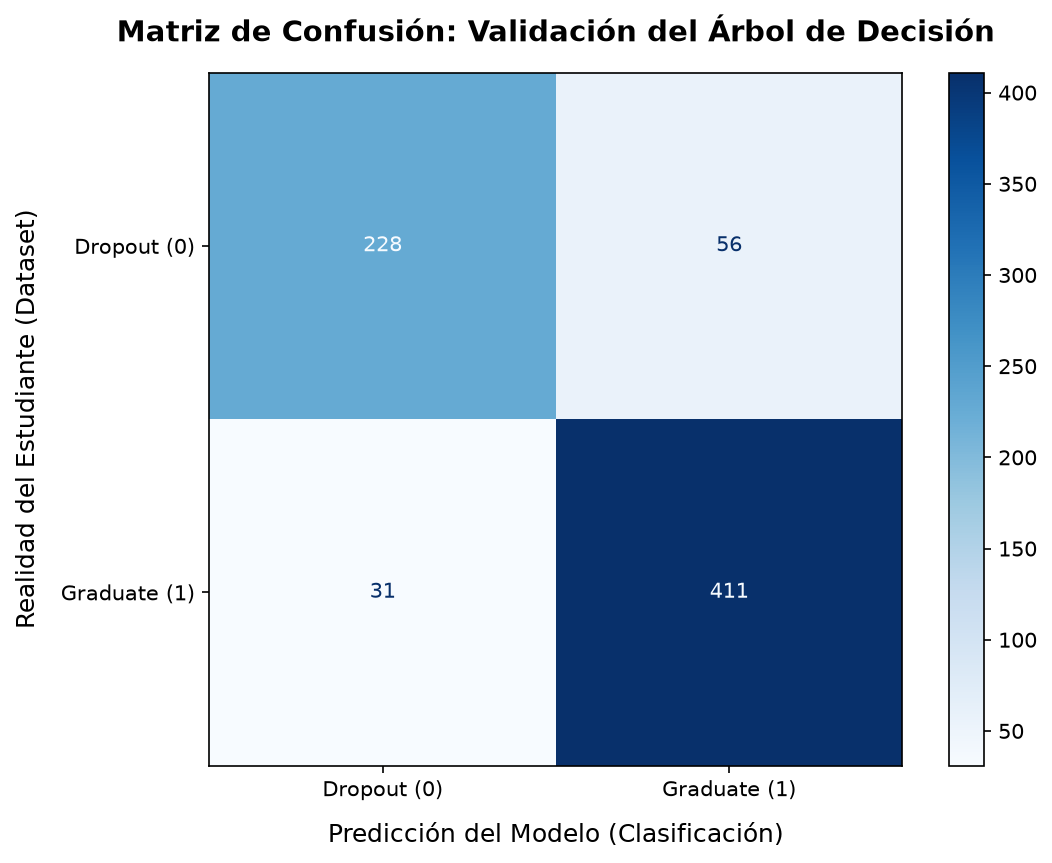

In [29]:
# 1. Tu código base (realizar predicciones)
y_pred = modelo_arbol.predict(X_test)

# 2. Calcular la matriz de confusión internamente
cm = confusion_matrix(y_test, y_pred)

# 1. Configurar el tamaño del gráfico
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

# 2. Diseñar el visualizador de la matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Dropout (0)', 'Graduate (1)'] # Etiquetas de tus clases binarias
)

# 3. Dibujar la matriz definiendo el estilo visual
# Usamos el mapa de colores 'Blues' (tonos azules), pero puedes usar 'Oranges' o 'Greens'
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')

# 4. Personalizar textos y títulos para la presentación de tu proyecto
plt.title("Matriz de Confusión: Validación del Árbol de Decisión", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Predicción del Modelo (Clasificación)", fontsize=12, labelpad=10)
plt.ylabel("Realidad del Estudiante (Dataset)", fontsize=12, labelpad=10)

# 6. Mostrar el gráfico en pantalla
plt.show()

### **Conclusión en palabras simples: matriz de confusión del Árbol de Decisión**

La matriz es una tabla de aciertos y errores: las filas son lo que realmente pasó y las columnas, lo que el modelo predijo. De 284 estudiantes que desertaron, el árbol **detectó a 228 y no detectó a 56**. De 442 que se graduaron, clasificó bien a 411 y marcó en riesgo a 31 por error (falsas alarmas). Es bueno identificando graduados, pero se le escapa casi 1 de cada 5 desertores.

## **REGRESIÓN LOGISTICA**

In [30]:
# 1. El modelo realiza las predicciones usando el set de prueba ESCALADO (X_test_scaled)
y_pred = modelo_logistico.predict(X_test_scaled)

# 2. Calcular e imprimir la Exactitud global (Accuracy)
accuracy = accuracy_score(y_test, y_pred)
print(f"1. Exactitud Global (Accuracy): {accuracy:.4f}")
print(
    f"   -> El {accuracy*100:.1f}% de todas las predicciones del modelo fueron correctas.\n"
)

# 3. Calcular la Matriz de Confusión
matriz = confusion_matrix(y_test, y_pred)
print("2. Matriz de Confusión Estructurada:")
print(matriz)
print("\nDesglose de la matriz aplicado a los estudiantes:")

# Extraer los valores de la matriz
tn, fp, fn, tp = matriz.ravel()

# Imprimir el significado real de cada cuadrante
print(
    f"   * Verdaderos Negativos (TN): {tn} -> Estudiantes en deserción correctamente identificados."
)
print(
    f"   * Falsos Positivos     (FP): {fp} -> Estudiantes que desertaron, pero el modelo predijo que se graduarían (Riesgo alto)."
)
print(
    f"   * Falsos Negativos     (FN): {fn} -> Estudiantes que se graduaron, pero el modelo predijo deserción."
)
print(
    f"   * Verdaderos Positivos (TP): {tp} -> Estudiantes graduados correctamente identificados."
)

print("\n" + "-" * 60)
# 4. Reporte de Clasificación Completo (Precision, Recall, F1-Score)
print("3. Reporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred, target_names=["Dropout", "Graduate"]))

1. Exactitud Global (Accuracy): 0.8857
   -> El 88.6% de todas las predicciones del modelo fueron correctas.

2. Matriz de Confusión Estructurada:
[[238  46]
 [ 37 405]]

Desglose de la matriz aplicado a los estudiantes:
   * Verdaderos Negativos (TN): 238 -> Estudiantes en deserción correctamente identificados.
   * Falsos Positivos     (FP): 46 -> Estudiantes que desertaron, pero el modelo predijo que se graduarían (Riesgo alto).
   * Falsos Negativos     (FN): 37 -> Estudiantes que se graduaron, pero el modelo predijo deserción.
   * Verdaderos Positivos (TP): 405 -> Estudiantes graduados correctamente identificados.

------------------------------------------------------------
3. Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

     Dropout       0.87      0.84      0.85       284
    Graduate       0.90      0.92      0.91       442

    accuracy                           0.89       726
   macro avg       0.88      0.88      0.88       726

### **GRAFICA LA MATRIZ DE CONFUSIÓN**

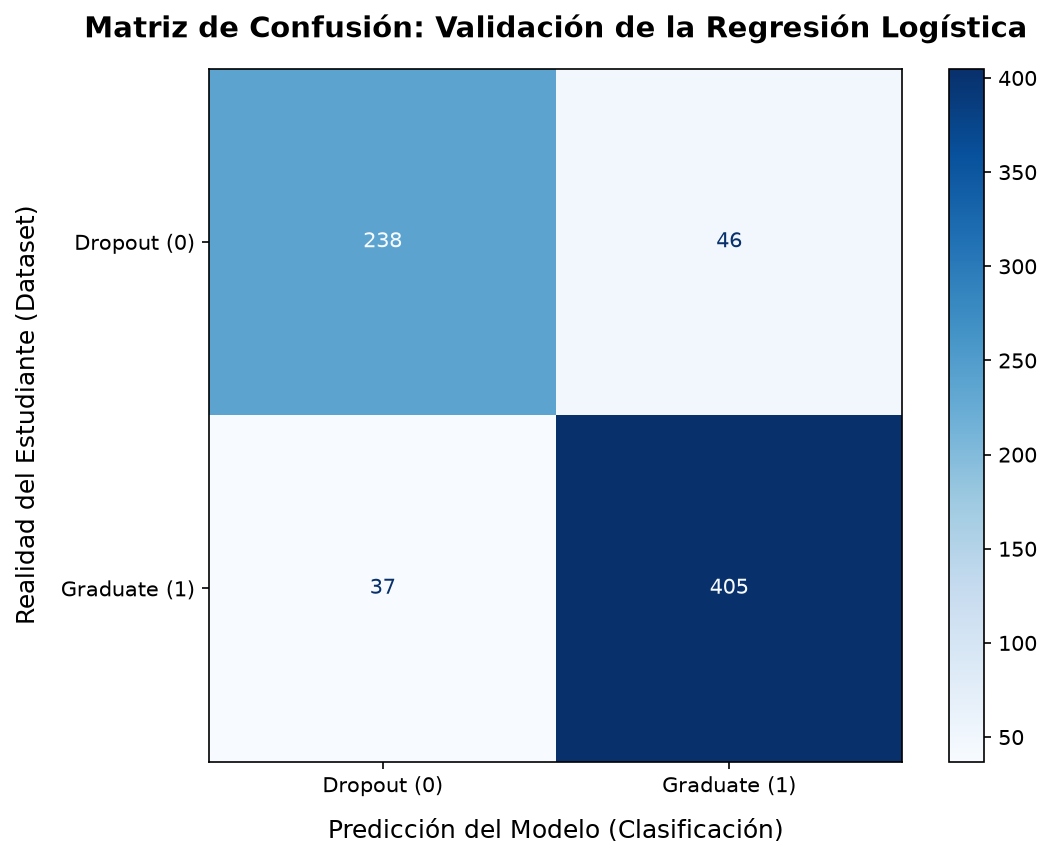

In [31]:
# 1. El modelo realiza las predicciones usando el set de prueba ESCALADO (X_test_scaled)
y_pred = modelo_logistico.predict(X_test_scaled)

# 2. Calcular la matriz de confusión internamente
cm = confusion_matrix(y_test, y_pred)

# 3. Configurar el tamaño del gráfico
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

# 4. Diseñar el visualizador de la matriz con las etiquetas correspondientes
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Dropout (0)", "Graduate (1)"],  # Clases de tu proyecto
)

# 5. Dibujar la matriz definiendo el estilo visual (tonos azules intensos)
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format="d")

# 6. Personalizar textos y títulos enfocados en la Regresión Logística
plt.title(
    "Matriz de Confusión: Validación de la Regresión Logística",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Predicción del Modelo (Clasificación)", fontsize=12, labelpad=10)
plt.ylabel("Realidad del Estudiante (Dataset)", fontsize=12, labelpad=10)

# 7. Mostrar el gráfico en pantalla limpia
plt.show()

### **Conclusión en palabras simples: matriz de confusión de la Regresión Logística**

De 284 estudiantes que desertaron, la regresión logística **detectó a 238 y no detectó a 46**; de 442 graduados, clasificó bien a 405 y marcó en riesgo a 37 por error. Es el modelo clásico que **encuentra más desertores**, a cambio de algunas falsas alarmas más. Como el costo de no ayudar a quien va a abandonar suele ser mayor que el de ofrecer apoyo de más, este resultado es útil para la institución.

## **Análisis de Sobreajuste (Train vs. Test)**

Para verificar que nuestros modelos tienen una buena capacidad de generalización y no están memorizando los datos, comparamos la exactitud (Accuracy) obtenida con los datos de entrenamiento frente a la de los datos de prueba.

In [12]:
# 1. Evaluar el Árbol de Decisión
acc_arbol_train = accuracy_score(y_train, modelo_arbol.predict(X_train))
acc_arbol_test = accuracy_score(y_test, modelo_arbol.predict(X_test))

# 2. Evaluar la Regresión Logística (usando datos escalados)
acc_log_train = accuracy_score(y_train, modelo_logistico.predict(X_train_scaled))
acc_log_test = accuracy_score(y_test, modelo_logistico.predict(X_test_scaled))

print("=== COMPARATIVA DE ACCURACY (TRAIN VS. TEST) ===")
print(f"Árbol de Decisión  - Train: {acc_arbol_train:.4f} | Test: {acc_arbol_test:.4f}")
print(f"Regresión Logística - Train: {acc_log_train:.4f} | Test: {acc_log_test:.4f}")

=== COMPARATIVA DE ACCURACY (TRAIN VS. TEST) ===
Árbol de Decisión  - Train: 0.8991 | Test: 0.8802
Regresión Logística - Train: 0.8860 | Test: 0.8857


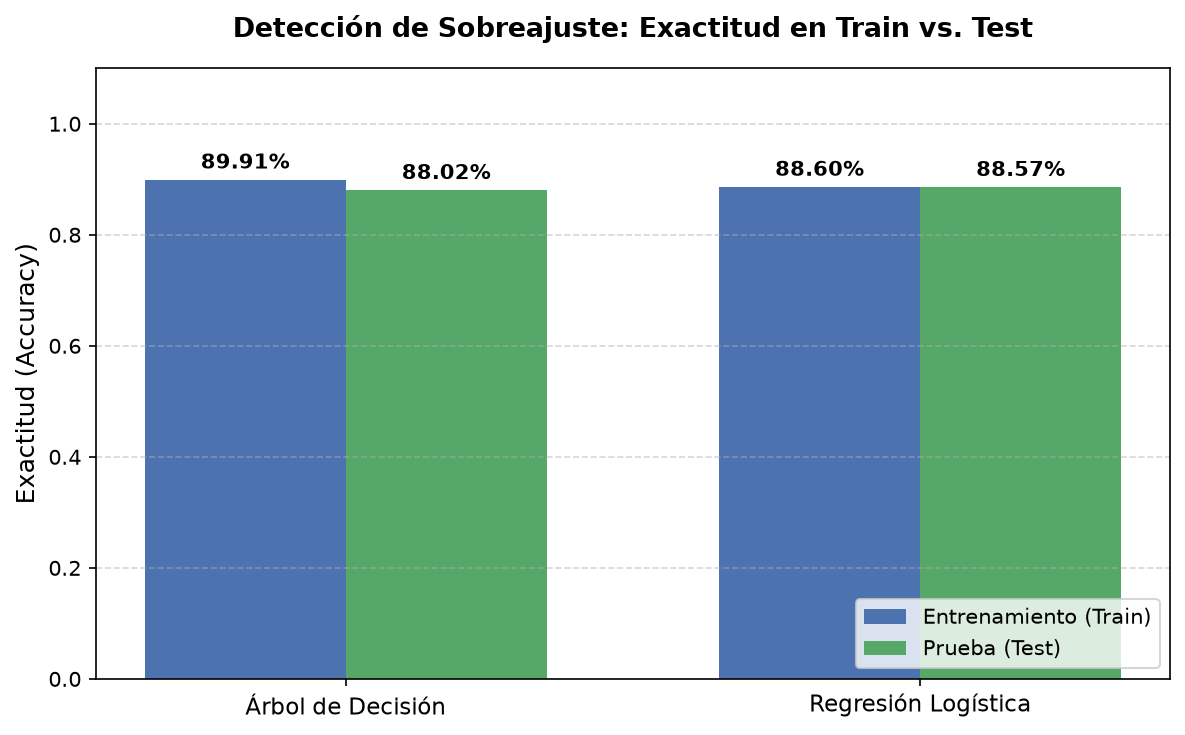

In [33]:
# Crear gráfica de barras comparativa
modelos = ['Árbol de Decisión', 'Regresión Logística']
train_accs = [acc_arbol_train, acc_log_train]
test_accs = [acc_arbol_test, acc_log_test]

x = np.arange(len(modelos))
ancho_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

barras_train = ax.bar(x - ancho_barra/2, train_accs, ancho_barra, label='Entrenamiento (Train)', color='#4c72b0')
barras_test = ax.bar(x + ancho_barra/2, test_accs, ancho_barra, label='Prueba (Test)', color='#55a868')

ax.set_ylabel('Exactitud (Accuracy)', fontsize=12)
ax.set_title('Detección de Sobreajuste: Exactitud en Train vs. Test', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Añadir etiquetas de texto sobre las barras
def etiquetar_barras(barras):
    for barra in barras:
        alto = barra.get_height()
        ax.annotate(f'{alto:.2%}',
                    xy=(barra.get_x() + barra.get_width() / 2, alto),
                    xytext=(0, 3),  # 3 puntos de desfase vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

etiquetar_barras(barras_train)
etiquetar_barras(barras_test)

plt.tight_layout()
plt.show()

### **Conclusión en palabras simples: entrenamiento frente a prueba**

Cada par de barras compara qué tan bien le va al modelo con los estudiantes con los que aprendió (entrenamiento) y con estudiantes que nunca vio (prueba). Si la barra de prueba fuera mucho más baja, el modelo habría **memorizado** en lugar de aprender. Aquí las barras son casi iguales: la Regresión Logística prácticamente no tiene diferencia y el Árbol de Decisión se separa unos 2 puntos. **Ambos modelos funcionan casi igual de bien con estudiantes nuevos.**

### **Diagnóstico del sobreajuste**

Compara las exactitudes de entrenamiento y prueba impresas por la celda anterior para los modelos reentrenados con nueve variables. Una brecha pequeña puede sugerir mejor estabilidad en esta partición, pero no demuestra por sí sola que el modelo generalice en todos los datos futuros. Las conclusiones y cifras deben actualizarse después de ejecutar de nuevo las celdas de modelado y evaluación.

# **PASO 5: Red Neuronal — Perceptrón Multicapa (MLP)**

Se entrena una red neuronal con **Keras/TensorFlow** usando los mismos datos que los modelos clásicos: las nueve variables, la partición 80/20 y los datos escalados con el `StandardScaler` ya ajustado (`X_train_scaled`, `X_test_scaled`). Así la comparación es justa y en Streamlit se reutiliza el mismo `scaler.pkl`.

**Arquitectura**

| Capa | Detalle |
|---|---|
| Entrada | 9 neuronas, una por característica |
| Oculta 1 | `Dense(32)` + ReLU + `Dropout(0.2)` |
| Oculta 2 | `Dense(16)` + ReLU + `Dropout(0.2)` |
| Salida | `Dense(2)` + Softmax |

Como se excluyó `Enrolled`, el problema es binario y la salida tiene **2 neuronas** con Softmax, una por clase (0 = Dropout, 1 = Graduate). Cada neurona devuelve la probabilidad de su clase y ambas suman 1.

In [13]:
from tensorflow import keras
from tensorflow.keras import layers

# Semilla para que el entrenamiento sea reproducible
keras.utils.set_random_seed(42)

# Construcción de la red: entrada -> 2 capas ocultas con Dropout -> salida Softmax
modelo_mlp = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),   # una neurona por característica
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(2, activation="softmax"),           # probabilidad de Dropout (0) y Graduate (1)
])

# Las etiquetas son enteros 0/1, por eso se usa sparse_categorical_crossentropy
modelo_mlp.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

modelo_mlp.summary()


I0000 00:00:1794541556.485467   12612 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794541565.243719   12612 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1794541566.781121   12612 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 882 (3.45 KB)

 Trainable params: 882 (3.45 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Se reserva 20% del entrenamiento para validar; el conjunto de prueba no se toca
# EarlyStopping detiene el entrenamiento cuando la pérdida de validación deja de mejorar
parada_temprana = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

historial = modelo_mlp.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[parada_temprana],
    verbose=0,
)

print(f"Épocas entrenadas: {len(historial.history['loss'])}")
print(f"Mejor pérdida de validación: {min(historial.history['val_loss']):.4f}")


Épocas entrenadas: 39
Mejor pérdida de validación: 0.2963


Convergencia en la época 29 de 39 entrenadas


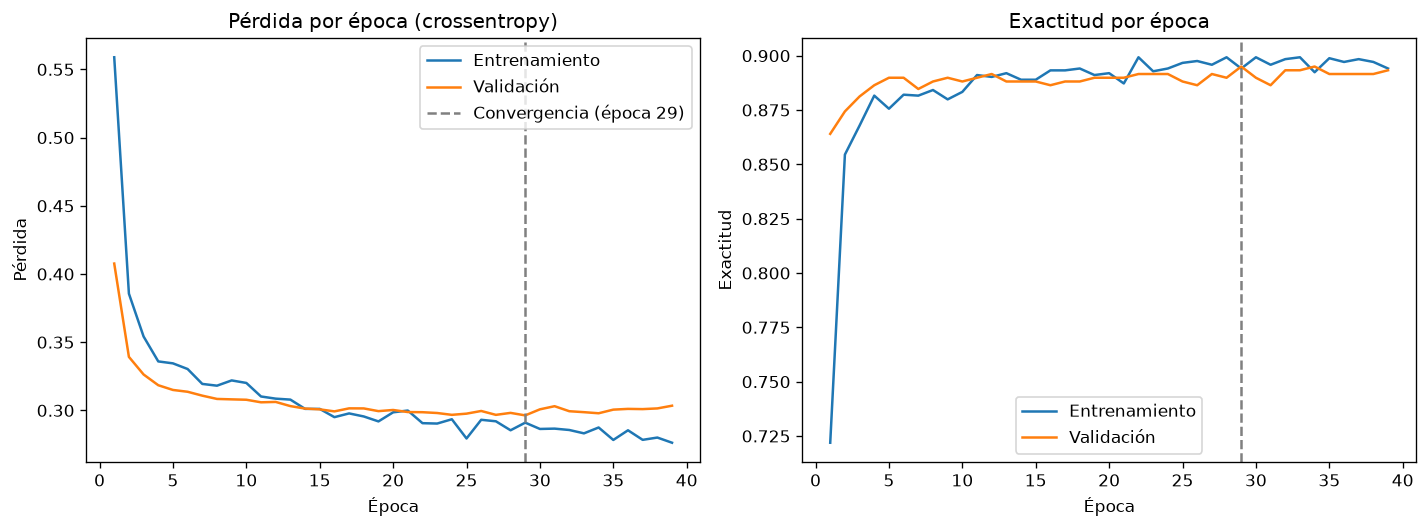

In [19]:
# Curvas de aprendizaje: sirven para detectar sobreajuste (train baja y validación sube)
# La convergencia se toma en la época con menor pérdida de validación
epoca_convergencia = int(np.argmin(historial.history["val_loss"])) + 1
print(f"Convergencia en la época {epoca_convergencia} de {len(historial.history['loss'])} entrenadas")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

ejes[0].plot(range(1, len(historial.history["loss"]) + 1), historial.history["loss"], label="Entrenamiento")
ejes[0].plot(range(1, len(historial.history["val_loss"]) + 1), historial.history["val_loss"], label="Validación")
ejes[0].axvline(epoca_convergencia, color="gray", linestyle="--", label=f"Convergencia (época {epoca_convergencia})")
ejes[0].set_title("Pérdida por época (crossentropy)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida")
ejes[0].legend()

ejes[1].plot(range(1, len(historial.history["accuracy"]) + 1), historial.history["accuracy"], label="Entrenamiento")
ejes[1].plot(range(1, len(historial.history["val_accuracy"]) + 1), historial.history["val_accuracy"], label="Validación")
ejes[1].axvline(epoca_convergencia, color="gray", linestyle="--")
ejes[1].set_title("Exactitud por época")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Exactitud")
ejes[1].legend()

plt.tight_layout()
plt.show()


### **Conclusión en palabras simples: curvas de aprendizaje de la red neuronal**

- **Pérdida (izquierda):** mide cuánto se equivoca la red; debe bajar a medida que aprende. La línea de validación usa estudiantes que la red no emplea para aprender.
- **Exactitud (derecha):** el porcentaje de aciertos en cada época; debe subir y luego estabilizarse.
- **Línea punteada:** marca la época 29, cuando la red dejó de mejorar con datos nuevos. El entrenamiento se detuvo solo en la 39 para no sobreentrenarse.

Las líneas de entrenamiento y validación van juntas, así que la red **aprendió patrones generales y no memorizó** a los estudiantes.

Exactitud (Accuracy) MLP - Train: 0.9019 | Test: 0.9022

Métricas de clasificación en el conjunto de prueba:
                Precisión  Sensibilidad (Recall)  F1-Score  Soporte
Dropout            0.9209                 0.8204    0.8678      284
Graduate           0.8922                 0.9548    0.9224      442
Promedio macro     0.9066                 0.8876    0.8951      726


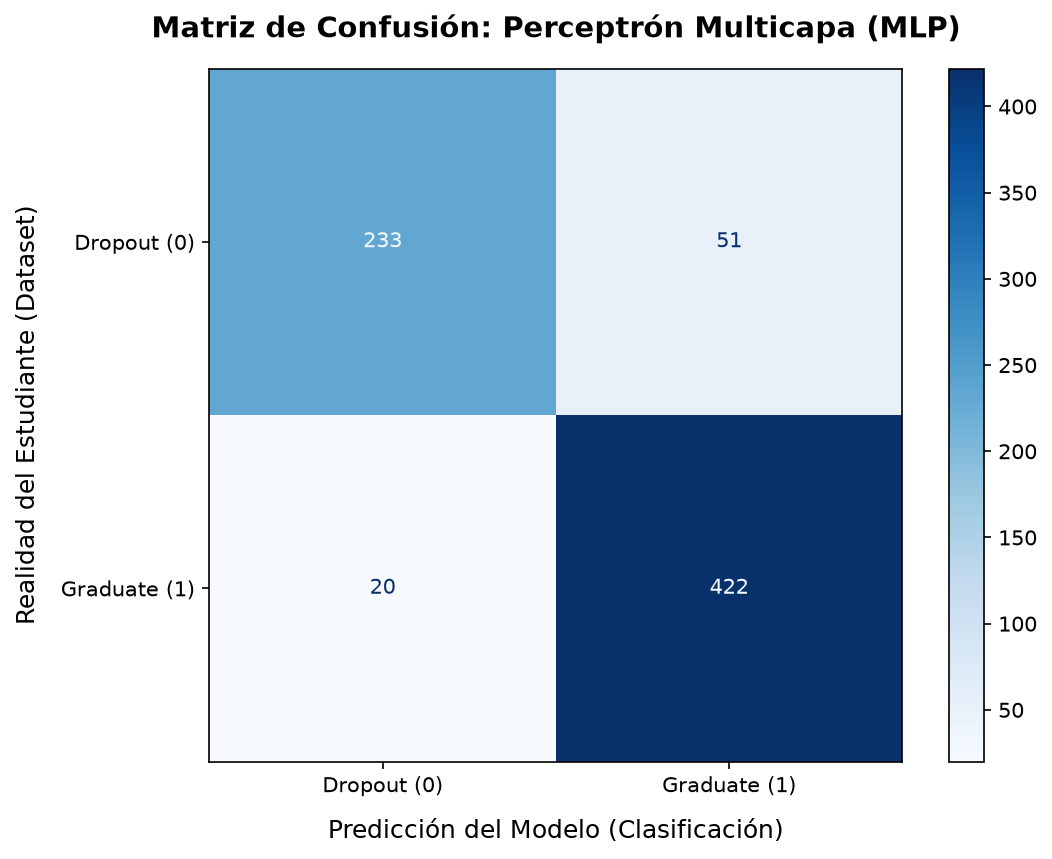

In [20]:
from sklearn.metrics import precision_recall_fscore_support

# Softmax devuelve una probabilidad por clase; la clase predicha es la de mayor probabilidad
probabilidades_mlp = modelo_mlp.predict(X_test_scaled, verbose=0)
y_pred_mlp = np.argmax(probabilidades_mlp, axis=1)

acc_mlp_train = accuracy_score(y_train, np.argmax(modelo_mlp.predict(X_train_scaled, verbose=0), axis=1))
acc_mlp_test = accuracy_score(y_test, y_pred_mlp)

print(f"Exactitud (Accuracy) MLP - Train: {acc_mlp_train:.4f} | Test: {acc_mlp_test:.4f}\n")

# Precisión, Sensibilidad (Recall) y F1-Score por clase y promedio macro
precision, recall, f1, soporte = precision_recall_fscore_support(y_test, y_pred_mlp)
metricas_mlp = pd.DataFrame(
    {"Precisión": precision, "Sensibilidad (Recall)": recall, "F1-Score": f1, "Soporte": soporte},
    index=["Dropout", "Graduate"],
)
metricas_mlp.loc["Promedio macro"] = [precision.mean(), recall.mean(), f1.mean(), soporte.sum()]
print("Métricas de clasificación en el conjunto de prueba:")
print(metricas_mlp.round(4))

# Matriz de confusión
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp, display_labels=["Dropout (0)", "Graduate (1)"]
).plot(cmap=plt.cm.Blues, ax=ax, values_format="d")
plt.title("Matriz de Confusión: Perceptrón Multicapa (MLP)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicción del Modelo (Clasificación)", fontsize=12, labelpad=10)
plt.ylabel("Realidad del Estudiante (Dataset)", fontsize=12, labelpad=10)
plt.show()


### **Conclusión en palabras simples: métricas y matriz de confusión del MLP**

- **Exactitud (90,22 %):** de cada 100 estudiantes, la red clasifica bien a unos 90.
- **Precisión:** cuando la red dice "este estudiante desertará", acierta 92 de cada 100 veces (0,92). Pocas falsas alarmas.
- **Sensibilidad (recall):** de todos los que realmente desertaron, la red detecta a 82 de cada 100 (0,82). Es la métrica clave, porque un desertor no detectado es un estudiante que no recibe ayuda.
- **F1-Score:** resume precisión y sensibilidad en un solo número (0,87 para desertores y 0,92 para graduados).

En la matriz: de 284 desertores, la red **detecta a 233 y no detecta a 51**; de 442 graduados, clasifica bien a 422 y marca en riesgo a 20 por error. Es la red que **menos se equivoca en total**, aunque todavía se le escapan algunos desertores.

In [17]:
# Comparativa final de los tres modelos sobre el mismo conjunto de prueba
comparativa = pd.DataFrame({
    "Modelo": ["Árbol de Decisión", "Regresión Logística", "MLP (red neuronal)"],
    "Exactitud Train": [acc_arbol_train, acc_log_train, acc_mlp_train],
    "Exactitud Test": [acc_arbol_test, acc_log_test, acc_mlp_test],
})
comparativa["Brecha Train-Test"] = comparativa["Exactitud Train"] - comparativa["Exactitud Test"]
comparativa.round(4)


,Modelo,Exactitud Train,Exactitud Test,Brecha Train-Test
0,Árbol de Decisión,0.8991,0.8802,0.0189
1,Regresión Logística,0.8860,0.8857,0.0003
2,MLP (red neuronal),0.9019,0.9022,-0.0003


### **Interpretación del MLP**

En esta ejecución (partición 80/20, `random_state=42`, semilla 42) el MLP obtuvo una exactitud de **90,22 %** en prueba, frente a 88,57 % de la Regresión Logística y 88,02 % del Árbol de Decisión. Con la matriz de confusión identificó correctamente a 233 de 284 desertores (recall 0,82) y a 422 de 442 graduados (recall 0,95).

- **Convergencia:** la función de costo es `sparse_categorical_crossentropy`, equivalente a `binary_crossentropy` para dos clases con salida Softmax. La menor pérdida de validación se alcanzó en la **época 29**; `EarlyStopping` detuvo el entrenamiento en la 39 y restauró los pesos de esa época.
- **Sin sobreajuste visible:** la exactitud de entrenamiento (90,19 %) y de prueba (90,22 %) son prácticamente iguales. Las curvas de pérdida bajan juntas y después de la época 29 la de validación se estabiliza mientras la de entrenamiento sigue bajando ligeramente, señal de que seguir entrenando no aportaría mejora.
- **Precisión y sensibilidad:** Dropout tiene precisión 0,92, recall 0,82 y F1 0,87; Graduate tiene precisión 0,89, recall 0,95 y F1 0,92. La red es algo mejor encontrando graduados que desertores.
- **Compromiso entre clases:** respecto a la Regresión Logística, el MLP detecta menos desertores (233 frente a 238) pero más graduados (422 frente a 405).
- **Cautela:** la mejora es de unos 1,7 puntos porcentuales sobre una sola partición y una sola inicialización; al cambiar la semilla el resultado puede variar ligeramente, por lo que no demuestra por sí sola una superioridad general.

### **Conclusiones generales**

| Modelo | Exactitud en prueba | Desertores detectados (de 284) |
|---|---|---|
| Árbol de Decisión | 88,02 % | 228 |
| Regresión Logística | 88,57 % | 238 |
| Red neuronal (MLP) | 90,22 % | 233 |

1. **Quién tiene más riesgo:** quienes se matriculan a mayor edad y quienes tienen notas bajas en el segundo semestre.
2. **Mejor modelo en general:** la red neuronal acierta más veces en total (9 de cada 10 estudiantes). La regresión logística detecta algunos desertores más.
3. **Confianza en los resultados:** ningún modelo muestra sobreajuste, así que su desempeño con estudiantes nuevos es similar al de la prueba.
4. **Uso recomendado:** los modelos son un apoyo para decidir a quién acompañar de forma temprana, no un veredicto sobre un estudiante. Las diferencias entre modelos provienen de una sola partición de datos y pueden variar al reentrenar.

## Exportación de artefactos para Streamlit

Ejecuta esta sección **después de volver a ejecutar el entrenamiento y la evaluación**. Guarda en la carpeta donde está `streamlit_app.py`, con los nombres que la aplicación espera:

- `modelo_logistico.pkl`, `modelo_arbol.pkl` y `scaler.pkl` (modelos clásicos y escalador).
- `modelo_mlp_pesos.npz` (pesos de la red neuronal; la app predice con ellos usando solo NumPy, por lo que **no necesita TensorFlow** al desplegar).
- `mlp_resultados.json` (curvas de pérdida, matriz de confusión y métricas de la red, para graficarlas en la app).
- `modelo_mlp.keras` (modelo completo de Keras, solo para uso local).

La celda verifica que los modelos estén configurados para las nueve variables en el orden establecido.

In [22]:
from pathlib import Path
import json
import joblib

# Buscar la carpeta del proyecto que contiene streamlit_app.py
project_dir = Path.cwd().resolve()
while not (project_dir / "streamlit_app.py").is_file() and project_dir != project_dir.parent:
    project_dir = project_dir.parent

if not (project_dir / "streamlit_app.py").is_file():
    raise FileNotFoundError(
        "No se encontró streamlit_app.py en la carpeta actual ni en sus carpetas superiores. "
        "Abre ACA_1.ipynb desde la carpeta del proyecto y vuelve a ejecutar esta celda."
    )

# Verificar que modelos y escalador correspondan a las nueve entradas de Streamlit
artefactos = {
    "modelo_logistico.pkl": modelo_logistico,
    "modelo_arbol.pkl": modelo_arbol,
    "scaler.pkl": scaler,
}

for nombre, artefacto in artefactos.items():
    cantidad_features = getattr(artefacto, "n_features_in_", None)
    if cantidad_features is not None and cantidad_features != len(FEATURE_COLUMNS):
        raise ValueError(
            f"{nombre} tiene {cantidad_features} variables; "
            f"se esperaban {len(FEATURE_COLUMNS)}. Vuelve a ejecutar el entrenamiento."
        )

    nombres_features = getattr(artefacto, "feature_names_in_", None)
    if nombres_features is not None and list(nombres_features) != FEATURE_COLUMNS:
        raise ValueError(
            f"El orden de variables de {nombre} no coincide con FEATURE_COLUMNS."
        )

# La red neuronal también debe esperar nueve entradas
if modelo_mlp.input_shape[-1] != len(FEATURE_COLUMNS):
    raise ValueError("modelo_mlp.keras no tiene nueve entradas. Vuelve a entrenar la red.")

# Guardar los tres archivos en la misma carpeta que consume streamlit_app.py
for nombre, artefacto in artefactos.items():
    ruta_salida = project_dir / nombre
    joblib.dump(artefacto, ruta_salida)
    print(f"Guardado: {ruta_salida}")

# Modelo completo de Keras (para reutilizarlo o seguir entrenándolo en local)
ruta_mlp = project_dir / "modelo_mlp.keras"
modelo_mlp.save(ruta_mlp)
print(f"Guardado: {ruta_mlp}")

# Pesos en NumPy: Streamlit predice con ellos sin necesitar TensorFlow
pesos = modelo_mlp.get_weights()   # [W1, b1, W2, b2, W3, b3]; el Dropout no tiene pesos
pesos_npz = {}
for i in range(0, len(pesos), 2):
    pesos_npz[f"W{i // 2 + 1}"] = pesos[i]
    pesos_npz[f"b{i // 2 + 1}"] = pesos[i + 1]
ruta_pesos = project_dir / "modelo_mlp_pesos.npz"
np.savez(ruta_pesos, **pesos_npz)
print(f"Guardado: {ruta_pesos}")

# Resultados de la red (curvas, matriz y métricas) para graficarlos en Streamlit sin reentrenar
resultados_mlp = {
    "epocas_entrenadas": len(historial.history["loss"]),
    "epoca_convergencia": epoca_convergencia,
    "historial": {k: [float(v) for v in valores] for k, valores in historial.history.items()},
    "matriz_confusion": cm_mlp.tolist(),
    "exactitud": {"train": float(acc_mlp_train), "test": float(acc_mlp_test)},
    "metricas": {
        clase: {
            "precision": float(fila["Precisión"]),
            "recall": float(fila["Sensibilidad (Recall)"]),
            "f1": float(fila["F1-Score"]),
            "soporte": int(fila["Soporte"]),
        }
        for clase, fila in metricas_mlp.iterrows()
    },
    "comparativa": {
        fila["Modelo"]: {"train": float(fila["Exactitud Train"]), "test": float(fila["Exactitud Test"])}
        for _, fila in comparativa.iterrows()
    },
}
ruta_resultados = project_dir / "mlp_resultados.json"
ruta_resultados.write_text(json.dumps(resultados_mlp, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Guardado: {ruta_resultados}")

print("\nArtefactos listos para Streamlit.")


Guardado: /ssd_datos/Projects/Python/ACA_1_AprendizajeAutomatico/modelo_logistico.pkl
Guardado: /ssd_datos/Projects/Python/ACA_1_AprendizajeAutomatico/modelo_arbol.pkl
Guardado: /ssd_datos/Projects/Python/ACA_1_AprendizajeAutomatico/scaler.pkl
Guardado: /ssd_datos/Projects/Python/ACA_1_AprendizajeAutomatico/modelo_mlp.keras
Guardado: /ssd_datos/Projects/Python/ACA_1_AprendizajeAutomatico/modelo_mlp_pesos.npz
Guardado: /ssd_datos/Projects/Python/ACA_1_AprendizajeAutomatico/mlp_resultados.json

Artefactos listos para Streamlit.
